# Experiment 5 · v2 pilot: which hold design removes pre-go drift?

**Date:** 2026-11-07 · **Agents:** `v2_base`, `v2_tight`, `v2_catch`, `v2_both` × seeds 1–3, plus `baseline_s1–3` (v1) for reference · **Status:** pilot (3 seeds per arm)

## Why
Experiments 1–4 showed three problems with the v1 hold period that matter for studying
preparation and the go cue:
1. the mass **drifts towards the target before the go cue** (overt preparation);
2. the hold is **anchored to x = 0**, not to the start, so off-centre starts fail (centre pull);
3. the agent sees the go cue with **no delay**, so it responds on the go step and reaction
   time (RT) is not a real quantity.

## What changed in v2 (all arms)
- **Random start in training:** x₀ ~ U[−0.5, 0.5]. The hold penalty and false-start check
  are relative to x₀, and the offset to the start (x₀ − x̂) is observed until the go cue is
  perceived, like a visible centre-hold target.
- **Sensory delay:** position and velocity arrive 2 steps (40 ms) late.
- **Cue delay:** the go signal arrives 4 steps (80 ms) late. RT must therefore be ≥ 80 ms.

## The arms (they differ only in how strictly the hold is enforced)
| arm | abort distance | catch trials |
| --- | --- | --- |
| `v2_base` | 0.15 (as v1) | none |
| `v2_tight` | **0.05** (= target tolerance) | none |
| `v2_catch` | 0.15 | **20%**: the go cue never comes; holding for 0.25–1.5 s pays +5 |
| `v2_both` | **0.05** | **20%** |

All runs: 4M steps, `max_steps` 600, everything else as v1 baseline.

## Measures
1. **Learning:** success, false-start rate and catch-hold rate over training.
2. **Competence** (gate): success on 512 trials from the training target distribution,
   from the centre and from random starts in ±0.5. Floor 0.90.
3. **Pre-go drift** on those trials: displacement and velocity towards the first target
   on the step before the go cue.
4. **Centre vs target pull:** the Experiment 3 hold probe, restricted to the trained range
   (starts ±0.4, offsets ±0.2/±0.4, 1 s hold, abort off). Fit v = b_centre·x₀ + b_target·(T − x₀).
5. **RT from the force command:** first step after go with |u| ≥ 2 (25% of u_max), by hold
   duration. Also the old velocity-based RT.
6. **Lookahead:** co-articulation index (CI) with T2 visible, and the T2-hidden control.
   v2 must still show lookahead to be usable.

In [1]:
from exp_tools import *
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

use_style()
pd.set_option("display.precision", 3)
ARMS = ["v2_base", "v2_tight", "v2_catch", "v2_both"]
GROUPS = {"v1 (baseline)": [f"baseline_s{s}" for s in (1, 2, 3)],
          **{a: [f"{a}_s{s}" for s in (1, 2, 3)] for a in ARMS}}
COL = {"v1 (baseline)": INK_SOFT, "v2_base": BLUE, "v2_tight": ORANGE,
       "v2_catch": AQUA, "v2_both": "#8e44ad"}
missing = [r for runs in GROUPS.values() for r in runs if not (RUNS / r / "checkpoint.pt").exists()]
print("missing checkpoints:", missing or "none")

missing checkpoints: none


## 1 · Learning curves

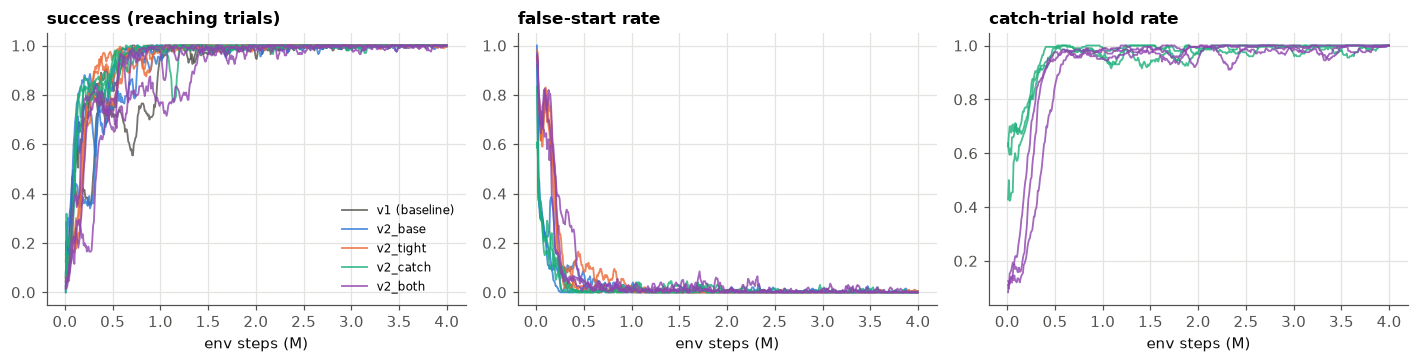

,group,run,success_rate,episodic_length,false_start_rate,catch_hold_rate
0,v1 (baseline),baseline_s1,1.000,112.970,NaN,NaN
1,v1 (baseline),baseline_s2,1.000,113.080,NaN,NaN
2,v1 (baseline),baseline_s3,0.995,110.535,NaN,NaN
3,v2_base,v2_base_s1,0.995,116.435,0.005,NaN
4,v2_base,v2_base_s2,1.000,121.715,0.000,NaN
5,v2_base,v2_base_s3,1.000,114.085,0.000,NaN
6,v2_tight,v2_tight_s1,1.000,118.260,0.000,NaN
7,v2_tight,v2_tight_s2,1.000,118.350,0.000,NaN
8,v2_tight,v2_tight_s3,0.995,119.050,0.005,NaN
9,v2_catch,v2_catch_s1,1.000,106.595,0.000,1.0


In [2]:
def log(run):
    return pd.read_json(RUNS / run / "train_log.jsonl", lines=True)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
for g, runs in GROUPS.items():
    for r in runs:
        d = log(r)
        kw = dict(color=COL[g], lw=1.2, alpha=0.8, label=g if r.endswith("_s1") else None)
        axs[0].plot(d.global_step / 1e6, d.success_rate, **kw)
        if "false_start_rate" in d:
            axs[1].plot(d.global_step / 1e6, d.false_start_rate, **kw)
        if "catch_hold_rate" in d and d.catch_hold_rate.notna().any():
            axs[2].plot(d.global_step / 1e6, d.catch_hold_rate, **kw)
for ax, t in zip(axs, ["success (reaching trials)", "false-start rate", "catch-trial hold rate"]):
    ax.set_title(t); ax.set_xlabel("env steps (M)")
axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

final = pd.DataFrame([{"group": g, "run": r, **log(r).iloc[-1][
    [c for c in ("success_rate", "false_start_rate", "catch_hold_rate", "episodic_length")
     if c in log(r).columns]].to_dict()} for g, runs in GROUPS.items() for r in runs])
final

## 2–6 · Evaluate every run

Competence from the centre and from random starts, pre-go drift, centre/target pull, RT and lookahead. About 20 s per run.

In [3]:
rows, rts = [], []
for g, runs in GROUPS.items():
    for r in runs:
        run = RUNS / r
        c0 = competence(run)
        c5 = competence(run, start_range=0.5)
        hp, *_ = hold_probe(run, starts=np.round(np.arange(-0.4, 0.41, 0.2), 2), hold_s=1.0)
        fit = drift_fit(hp)
        rt = reaction_times_u(run); rt["group"], rt["run"] = g, r
        rts.append(rt)
        la = lookahead(run)
        rows.append({"group": g, "run": r,
                     "succ_centre": c0["success_rate"], "multi_centre": c0["success_multi_target"],
                     "succ_random": c5["success_rate"], "fs_random": c5["false_start_rate"],
                     "drift_x_centre": c0["drift_x_to_target"], "drift_v_centre": c0["drift_v_to_target"],
                     "drift_x_random": c5["drift_x_to_target"], "drift_abs_random": c5["drift_abs"],
                     "b_centre": fit["b_centre"], "b_target": fit["b_target"],
                     "rt_u_ms": rt.rt_u_ms.mean(), "rt_v_ms": rt.rt_v_ms.mean(),
                     **la})
        print(f"{r:<16s} succ {c0['success_rate']:.3f}/{c5['success_rate']:.3f}  "
              f"drift {c0['drift_x_to_target']:+.4f}  CI {la['ci']:+.3f}  RT_u {rt.rt_u_ms.mean():.0f} ms")
ev = pd.DataFrame(rows)
rt_all = pd.concat(rts, ignore_index=True)
ev.to_csv("exp05_v2_pilot_eval.csv", index=False)

baseline_s1      succ 0.998/0.941  drift +0.0139  CI +0.622  RT_u 1 ms


baseline_s2      succ 1.000/0.959  drift -0.0010  CI +0.606  RT_u 4 ms


baseline_s3      succ 0.994/0.980  drift +0.0138  CI +0.238  RT_u 1 ms


v2_base_s1       succ 1.000/1.000  drift +0.0002  CI +0.944  RT_u 80 ms


v2_base_s2       succ 1.000/1.000  drift +0.0037  CI +0.394  RT_u 82 ms


v2_base_s3       succ 1.000/1.000  drift +0.0031  CI +0.381  RT_u 73 ms


... (5 outputs left out)

v2_catch_s3      succ 1.000/1.000  drift -0.0015  CI +0.686  RT_u 87 ms


v2_both_s1       succ 1.000/0.998  drift +0.0064  CI +0.730  RT_u 78 ms


v2_both_s2       succ 1.000/1.000  drift -0.0008  CI +0.448  RT_u 77 ms


v2_both_s3       succ 0.996/0.998  drift -0.0055  CI +0.520  RT_u 88 ms


### Per run

In [4]:
ev.set_index(["group", "run"])

succ_centre  multi_centre  succ_random  fs_random  \
group         run                                                              
v1 (baseline) baseline_s1        0.998         0.997        0.941      0.057   
              baseline_s2        1.000         1.000        0.959      0.039   
              baseline_s3        0.994         0.992        0.980      0.018   
v2_base       v2_base_s1         1.000         1.000        1.000      0.000   
              v2_base_s2         1.000         1.000        1.000      0.000   
              v2_base_s3         1.000         1.000        1.000      0.000   
v2_tight      v2_tight_s1        0.994         0.992        0.992      0.000   
              v2_tight_s2        1.000         1.000        1.000      0.000   
              v2_tight_s3        1.000         1.000        1.000      0.000   
v2_catch      v2_catch_s1        1.000         1.000        1.000      0.000   
              v2_catch_s2        1.000         1.000        1.000      0.000   
              v2_catch_s3        1.000         1.000        1.000      0.000   
v2_both       v2_both_s1         1.000         1.000        0.998      0.000   
              v2_both_s2         1.000         1.000        1.000      0.000   
              v2_both_s3         0.996         0.995        0.998      0.000   

                           drift_x_centre  drift_v_centre  drift_x_random  \
group         run                                                           
v1 (baseline) baseline_s1       1.391e-02       3.576e-02       3.829e-02   
              baseline_s2      -1.033e-03       4.887e-03       2.289e-02   
              baseline_s3       1.379e-02       3.157e-02       2.248e-02   
v2_base       v2_base_s1        1.773e-04       7.917e-03      -4.268e-05   
              v2_base_s2        3.652e-03       5.717e-03       4.736e-03   
              v2_base_s3        3.071e-03       4.248e-03       2.976e-03   
v2_tight      v2_tight_s1       1.692e-03       1.018e-03       2.974e-03   
              v2_tight_s2       6.162e-03       3.646e-03       7.299e-03   
              v2_tight_s3       1.376e-02       1.367e-02       1.418e-02   
v2_catch      v2_catch_s1      -1.039e-04      -2.477e-04       4.442e-04   
              v2_catch_s2      -4.316e-03       7.639e-03      -5.765e-03   
              v2_catch_s3      -1.496e-03       9.514e-04      -1.402e-03   
v2_both       v2_both_s1        6.395e-03       7.735e-03       6.979e-03   
              v2_both_s2       -8.116e-04       3.277e-03      -2.113e-04   
              v2_both_s3       -5.543e-03      -1.139e-03      -6.345e-03   

                           drift_abs_random   b_centre   b_target  rt_u_ms  \
group         run                                                            
v1 (baseline) baseline_s1             0.052 -4.005e-01  7.942e-02      0.7   
              baseline_s2             0.038 -1.954e-01 -1.395e-02      3.9   
              baseline_s3             0.026 -6.758e-02  8.155e-02      0.7   
v2_base       v2_base_s1              0.004  3.302e-03  3.188e-03     79.5   
              v2_base_s2              0.005 -1.078e-02  1.701e-02     82.4   
              v2_base_s3              0.011 -2.519e-02  4.294e-02     72.6   
v2_tight      v2_tight_s1             0.004 -4.159e-03  1.024e-04     81.1   
              v2_tight_s2             0.007 -3.996e-03  7.131e-03     78.9   
              v2_tight_s3             0.015  2.330e-03  6.790e-02     76.4   
v2_catch      v2_catch_s1             0.014  9.952e-03 -1.442e-02     84.2   
              v2_catch_s2             0.008  2.267e-03 -7.912e-03     82.4   
              v2_catch_s3             0.013  3.452e-02 -4.420e-02     86.8   
v2_both       v2_both_s1              0.009  1.212e-02  1.166e-02     77.6   
              v2_both_s2              0.004  6.312e-04  6.255e-03     77.4   
              v2_both_s3              0.009  1.109e-02 -3.859e-02     88.3   

                           rt

### Per arm (mean over 3 seeds)

Competence first: an arm below the 0.90 floor is not interpretable on the other measures.

In [5]:
cols = ["succ_centre", "multi_centre", "succ_random", "fs_random", "drift_x_centre",
        "drift_v_centre", "drift_abs_random", "b_centre", "b_target", "rt_u_ms", "ci", "ci_control"]
arm = ev.groupby("group", sort=False)[cols].mean()
arm["competent seeds"] = ev.assign(c=(ev.succ_centre >= 0.9) & (ev.succ_random >= 0.9)).groupby("group", sort=False).c.sum().astype(int).astype(str) + "/3"
arm

,succ_centre,multi_centre,succ_random,fs_random,drift_x_centre,drift_v_centre,drift_abs_random,b_centre,b_target,rt_u_ms,ci,ci_control,competent seeds
group,,,,,,,,,,,,,
v1 (baseline),0.997,0.996,0.960,0.038,8.888e-03,0.024,0.039,-0.221,0.049,1.767,0.489,7.201e-33,3/3
v2_base,1.000,1.000,1.000,0.000,2.300e-03,0.006,0.007,-0.011,0.021,78.167,0.573,4.419e-33,3/3
v2_tight,0.998,0.997,0.997,0.000,7.205e-03,0.006,0.009,-0.002,0.025,78.800,0.733,4.419e-33,3/3
v2_catch,1.000,1.000,1.000,0.000,-1.972e-03,0.003,0.011,0.016,-0.022,84.467,0.725,-1.440e-32,3/3
v2_both,0.999,0.998,0.999,0.000,1.323e-05,0.003,0.007,0.008,-0.007,81.100,0.566,-1.800e-32,3/3


## Pre-go drift, centre pull and lookahead, per seed

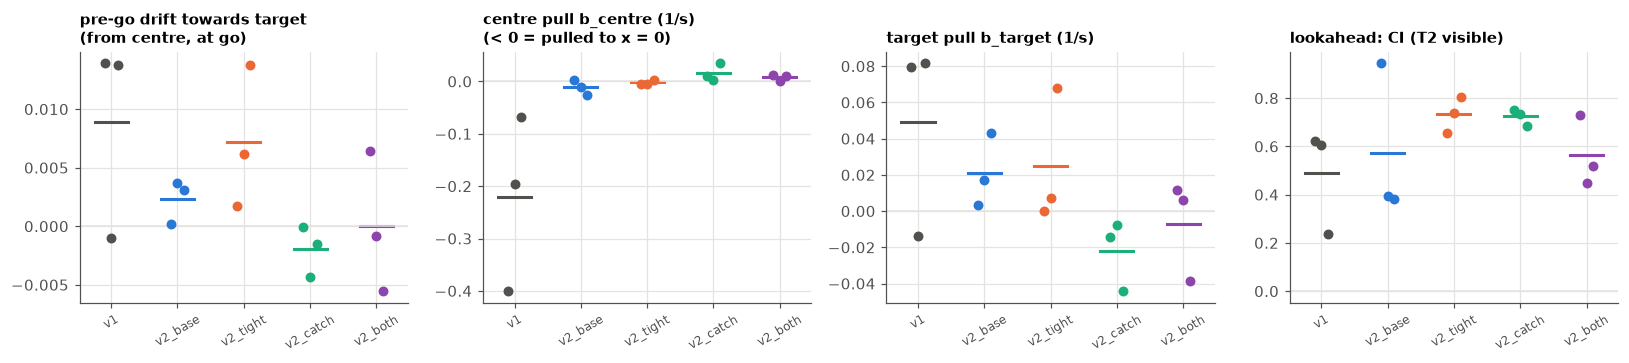

In [6]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
order = list(GROUPS)
for k, (col, title) in enumerate([("drift_x_centre", "pre-go drift towards target\n(from centre, at go)"),
                                  ("b_centre", "centre pull b_centre (1/s)\n(< 0 = pulled to x = 0)"),
                                  ("b_target", "target pull b_target (1/s)"),
                                  ("ci", "lookahead: CI (T2 visible)")]):
    ax = axs[k]
    for j, g in enumerate(order):
        y = ev[ev.group == g][col]
        ax.scatter(np.full(len(y), j) + np.linspace(-0.1, 0.1, len(y)), y, color=COL[g], s=30, zorder=3)
        ax.plot([j - 0.25, j + 0.25], [y.mean()] * 2, color=COL[g], lw=2)
    ax.axhline(0, color=GRID, lw=1)
    ax.set_xticks(range(len(order)), [o.replace(" (baseline)", "") for o in order], rotation=30, fontsize=8)
    ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.show()

## Reaction time by hold duration

RT from the force command (first |u| ≥ 2 after the go step). v2 cannot respond before the cue reaches it (80 ms).

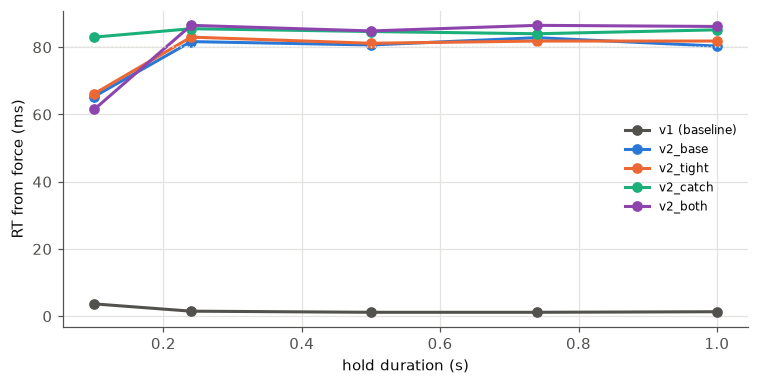

mean                           std                        
delay_s        0.10  0.24  0.50  0.74  1.00  0.10  0.24  0.50  0.74  1.00
group                                                                    
v1 (baseline)   4.0   2.0   1.0   1.0   1.0   9.0   5.0   5.0   5.0   5.0
v2_base        65.0  82.0  81.0  83.0  80.0  35.0   8.0   6.0  12.0   3.0
v2_tight       66.0  83.0  81.0  82.0  82.0  40.0  11.0   7.0   8.0   6.0
v2_catch       83.0  86.0  85.0  84.0  85.0  21.0  13.0  10.0  10.0   9.0
v2_both        62.0  86.0  85.0  86.0  86.0  40.0  11.0   9.0  12.0  11.0

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for g in GROUPS:
    m = rt_all[rt_all.group == g].groupby("delay_s").rt_u_ms.mean()
    ax.plot(m.index, m.values, "o-", color=COL[g], label=g)
ax.axhline(80, color=GRID, ls=":", lw=1)
ax.set_xlabel("hold duration (s)"); ax.set_ylabel("RT from force (ms)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
rt_all.groupby(["group", "delay_s"], sort=False).rt_u_ms.agg(["mean", "std"]).unstack("delay_s").round(0)

## Conclusion

**All four v2 designs work, and `v2_catch` is the best of them. Random-start training removes
the centre pull, catch trials remove the target pull, and the tight abort is not needed.**

| | v1 | v2_base | v2_tight | v2_catch | v2_both |
| --- | --- | --- | --- | --- | --- |
| competent seeds (centre and random start) | 3/3 | 3/3 | 3/3 | 3/3 | 3/3 |
| success from random starts | 0.960 | 1.000 | 0.997 | 1.000 | 0.999 |
| pre-go drift towards target, from centre | +0.009 | +0.002 | +0.007 | **−0.002** | **0.000** |
| drift velocity at go (towards target) | 0.024 | 0.006 | 0.006 | **0.003** | **0.003** |
| centre pull b_centre (1/s) | **−0.22** | −0.01 | −0.00 | +0.02 | +0.01 |
| target pull b_target (1/s) | +0.049 | +0.021 | +0.025 | **−0.022** | **−0.007** |
| RT from force (ms, mean) | **1** | 78 | 79 | 84 | 81 |
| CI with T2 visible | 0.49 | 0.57 | 0.73 | **0.73** | 0.57 |
| CI with T2 hidden (control) | 0 | 0 | 0 | 0 | 0 |

1. **Training is not harder.** Every arm reaches success ≥ 0.995 in training and ≥ 0.99 at
   evaluation, from the centre and from random starts, with no false starts. The tight-abort
   arms pass through ~80% false starts early in training but clear them by 0.5–1M steps.
2. **The centre pull is gone in every v2 arm** (|b_centre| ≤ 0.035, against −0.22 in v1 and
   −0.40 in baseline_s1). Training from random starts with a visible start marker is
   enough; the hold design does not matter for this.
3. **The target pull and pre-go drift go away only with catch trials.** Without catch trials
   the drift towards the target shrinks from v1 but persists in some seeds: v2_tight_s3
   drifts as much as v1 (+0.014). With catch trials the signed drift and the target pull are
   about zero in every seed, and their small residuals point either way. *What remains in
   all v2 arms is a small undirected drift (mean |drift| 0.007–0.011, about a fifth of the
   target tolerance), against 0.039 in v1.*
4. **RT is now a real quantity, but almost entirely the cue delay.** The force command
   rises 78–88 ms after the go step, which is the 80 ms cue delay plus at most one step. The
   network still reacts on the first step it perceives the cue. RT does not fall with hold
   duration in any arm. The only exception is the 0.10 s hold, shorter than any trained
   hold, where the arms without catch trials anticipate (RT ≈ 62–66 ms, before the cue can
   have been seen) and **`v2_catch` does not (83 ms)**.
5. **Lookahead survives and is, if anything, stronger.** The CI is positive in all 12 v2
   runs (0.38–0.94) with an exactly-zero T2-hidden control. v2_catch and v2_tight have the
   highest and most consistent CI (0.66–0.80).

**Recommendation: adopt `v2_catch` as the v2 configuration** (random start ±0.5 with a start
marker, 40 ms sensory delay, 80 ms cue delay, 20% catch trials, abort at 0.15). It is the only
arm that is best or tied on every measure: no centre pull, no target pull, ~zero signed drift,
no anticipation, and high, consistent lookahead. Adding the tight abort (`v2_both`) buys
nothing and makes the CI more seed-variable (0.45–0.73).

**Open issues for the next step**
- RT has no component beyond the cue delay. If RT effects matter scientifically (for example
  a decrease with preparation time), something in the task has to make preparation take
  time. That is a separate design question, not settled here.
- The residual undirected drift (~0.01) is small but not zero. Neural analyses of the hold
  should still control for x and v.
- Pilot only: 3 seeds per arm. The chosen configuration needs the full 8 seeds before its
  numbers go into the results document.

*Limits: noiseless plant and mean action at evaluation; hold probe restricted to the trained
range (starts ±0.4, 1 s holds); RT threshold |u| ≥ 2 is a choice.*